# Pluie de demain: starter notebook

Will it rain tomorrow at each of the ~3000 Météo-France stations, and how much?

This notebook gives a working baseline, the reference you have to beat in both tracks:
1. load the data and look at the target (lots of zeros, a heavy tail);
2. compress the SYNOP *map of the day* (hundreds of correlated columns) with a PCA, 20 components chosen arbitrarily;
3. compare a **direct regression** with a **hurdle model** (classification, then regression on rainy days);
4. a first look at the **distribution shifts** of the test set;
5. write the two submissions: rain amount (track 1, RMSLE) and probability of rain (track 2, Brier score).

Validation is **temporal** (the last training year): never shuffle days. It does **not** reproduce the shifts of
the test set (new stations, missing map stations): designing a validation that does is part of your work.

It uses gradient boosting only. GLMs, GAMs, regularisation, the choice of the number of components, analogues,
weather regimes, calibration and the shifts are left to you. What comes from this notebook earns no points by itself.

In [1]:
import os, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import log_loss

def find_data():
    # on Kaggle: the folder of the competition data under /kaggle/input, whatever the competition's name
    if os.environ.get("PDD_DATA"):
        return Path(os.environ["PDD_DATA"])
    hits = sorted(Path("/kaggle/input").glob("**/train.parquet"))
    if not hits:
        raise FileNotFoundError("train.parquet not found under /kaggle/input: add the competition data (Input panel)")
    return hits[0].parent

DATA = find_data()
print("data:", DATA)
SAMPLE = int(os.environ.get("PDD_SAMPLE", 2_000_000))   # rows used for model selection (ML at scale!)
THRESHOLD = 1.0                                          # a rainy day: RR >= 1 mm

def rmsle(y, p):
    return float(np.sqrt(np.mean((np.log1p(np.clip(p, 0, None)) - np.log1p(y)) ** 2)))

data: \kaggle\input\pluie-de-demain


## 1. The data

In [2]:
t0 = time.time()
train = pd.read_parquet(DATA / "train.parquet")
test = pd.read_parquet(DATA / "test.parquet")
maps = pd.read_parquet(DATA / "maps.parquet")
stations = pd.read_csv(DATA / "stations.csv", dtype={"station": str})
print(f"train {train.shape}, test {test.shape}, maps {maps.shape}, {len(stations)} stations, {time.time() - t0:.0f} s")
print(f"train memory: {train.memory_usage(deep=True).sum() / 1e9:.2f} GB")
train.head()

train (6888953, 20), test (149108, 19), maps (4838, 334), 1660 stations, 2 s
train memory: 0.81 GB


,id,station,target_date,rr_lag4,rr_lag5,rr_lag6,rr_lag7,rr_lag8,rr_lag9,rr_lag10,tn_lag4,tx_lag4,ffm_lag4,rr,lat,lon,alt,dep,doy,month
0,01014002_20100101,01014002,2010-01-01,3.2,0.4,0.0,0.6,15.0,9.4,23.0,-0.5,8.8,2.4,11.0,46.278168,5.669,534.0,01,1,1
1,01014002_20100102,01014002,2010-01-02,8.6,3.2,0.4,0.0,0.6,15.0,9.4,4.1,13.2,4.2,0.6,46.278168,5.669,534.0,01,2,1
2,01014002_20100103,01014002,2010-01-03,4.2,8.6,3.2,0.4,0.0,0.6,15.0,8.2,11.6,3.0,0.2,46.278168,5.669,534.0,01,3,1
3,01014002_20100104,01014002,2010-01-04,12.4,4.2,8.6,3.2,0.4,0.0,0.6,2.4,11.5,1.5,1.0,46.278168,5.669,534.0,01,4,1
4,01014002_20100105,01014002,2010-01-05,11.0,12.4,4.2,8.6,3.2,0.4,0.0,0.0,4.9,1.0,0.2,46.278168,5.669,534.0,01,5,1


rainy days (RR >= 1 mm): 32.1%   dry days with RR = 0: 50.0%


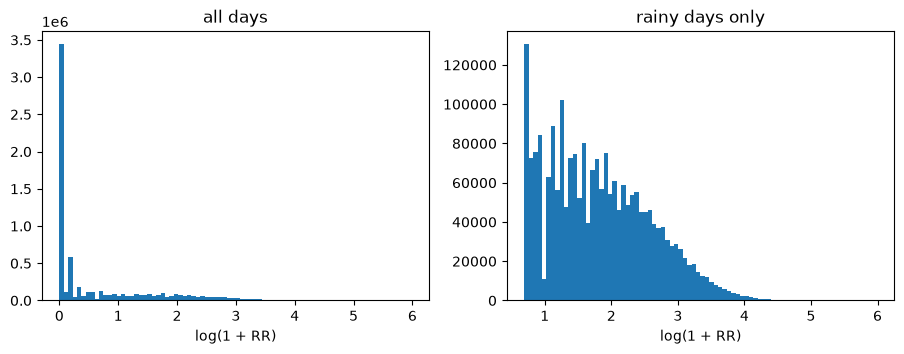

In [3]:
rain = train["rr"] >= THRESHOLD
print(f"rainy days (RR >= 1 mm): {rain.mean():.1%}   dry days with RR = 0: {(train['rr'] == 0).mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log1p(train["rr"]), bins=80); axes[0].set_xlabel("log(1 + RR)"); axes[0].set_title("all days")
axes[1].hist(np.log1p(train.loc[rain, "rr"]), bins=80); axes[1].set_xlabel("log(1 + RR)"); axes[1].set_title("rainy days only")
plt.show()

## 2. The map of the day: hundreds of correlated columns -> PCA

`maps.parquet` has one row per target date: the SYNOP observations of day T-2 (pressure, 24-h pressure change,
temperature, humidity, wind, clouds, rain) at each SYNOP station. The same row is shared by all stations of the day.

c:\Users\gdest\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['n_07005' 'n_07558']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


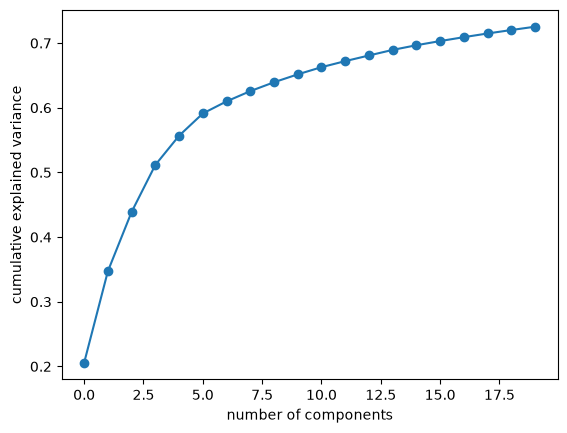

333 map columns -> 20 components (73% of the variance)


c:\Users\gdest\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['n_07005' 'n_07558']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [4]:
map_cols = [c for c in maps.columns if c != "target_date"]
VAL_START = pd.Timestamp(train["target_date"].max().year, 1, 1)          # last training year = validation
fit_dates = maps["target_date"] < VAL_START
map_pca = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(n_components=20, random_state=0))
map_pca.fit(maps.loc[fit_dates, map_cols])
ev = map_pca[-1].explained_variance_ratio_
plt.plot(np.cumsum(ev), "o-"); plt.xlabel("number of components"); plt.ylabel("cumulative explained variance"); plt.show()
Z = pd.DataFrame(map_pca.transform(maps[map_cols]), index=maps["target_date"]).add_prefix("pc")
print(f"{len(map_cols)} map columns -> {Z.shape[1]} components ({ev.sum():.0%} of the variance)")

In [5]:
row_cols = [c for c in train.columns if c not in ("id", "station", "target_date", "rr", "dep")]
def design(df):
    X = df.join(Z, on="target_date")
    return X[row_cols + list(Z.columns)].to_numpy(dtype="float32")

tr = train[train["target_date"] < VAL_START]
va = train[train["target_date"] >= VAL_START]
if len(tr) > SAMPLE:
    tr = tr.sample(SAMPLE, random_state=0)
X_tr, X_va = design(tr), design(va)
y_tr, y_va = tr["rr"].to_numpy(), va["rr"].to_numpy()
print(X_tr.shape, X_va.shape, row_cols)

(2000000, 35) (530192, 35) ['rr_lag4', 'rr_lag5', 'rr_lag6', 'rr_lag7', 'rr_lag8', 'rr_lag9', 'rr_lag10', 'tn_lag4', 'tx_lag4', 'ffm_lag4', 'lat', 'lon', 'alt', 'doy', 'month']


## 3. Baselines, direct regression, hurdle model

In [6]:
# climatology: mean of log(1 + RR) per station and month (the best constant for the RMSLE)
clim = tr.assign(l1p=np.log1p(tr["rr"])).groupby(["station", "month"])["l1p"].mean().rename("clim")
pred_clim = np.expm1(va.join(clim, on=["station", "month"])["clim"].fillna(np.log1p(tr["rr"]).mean()))
print(f"climatology            RMSLE {rmsle(y_va, pred_clim):.4f}")

# direct regression of log(1 + RR)
direct = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=0)
direct.fit(X_tr, np.log1p(y_tr))
pred_direct = np.expm1(np.clip(direct.predict(X_va), 0, None))
print(f"direct regression      RMSLE {rmsle(y_va, pred_direct):.4f}")

climatology            RMSLE 0.8594
direct regression      RMSLE 0.8264


In [7]:
# hurdle model: P(rain) then E[log1p RR | rain]
rain_tr = y_tr >= THRESHOLD
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0).fit(X_tr, rain_tr)
reg = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=0).fit(X_tr[rain_tr], np.log1p(y_tr[rain_tr]))
m0 = np.log1p(y_tr[~rain_tr]).mean()          # E[log1p RR | no rain]: a few tenths of mm

p_va = clf.predict_proba(X_va)[:, 1]
m1_va = np.clip(reg.predict(X_va), 0, None)
pred_hurdle = np.expm1(p_va * m1_va + (1 - p_va) * m0)    # E[log1p RR], the optimum of the RMSLE
print(f"hurdle model           RMSLE {rmsle(y_va, pred_hurdle):.4f}")
print(f"  classifier log-loss {log_loss(y_va >= THRESHOLD, p_va):.4f}  (climatology frequency: "
      f"{log_loss(y_va >= THRESHOLD, np.full(len(y_va), rain_tr.mean())):.4f})")

hurdle model           RMSLE 0.8190
  classifier log-loss 0.5400  (climatology frequency: 0.5906)


In [8]:
rain_va = (y_va >= THRESHOLD).astype(int)
print(f"Brier score of the hurdle classifier (track 2): {np.mean((p_va - rain_va) ** 2):.4f}")

Brier score of the hurdle classifier (track 2): 0.1809


**Questions.** Why is $\exp(p\,m_1 + (1-p)\,m_0) - 1$ the right way to combine the two models for the RMSLE,
and not $p \times$ (predicted rain if it rains)? Is the Brier score above good? Compared with what? Are the
probabilities calibrated? Look at the errors by season and by region.

## 4. The test set is not the training set

Three shifts are built into the competition: the test years come later, some test stations are **absent from the
training data**, and some SYNOP stations of the map **stop reporting** during the test period. A first look:

test rows whose station is in train.parquet: 87.8%
new stations: 203, departments [np.int64(7), np.int64(11), np.int64(20), np.int64(30), np.int64(34), np.int64(48), np.int64(66)]


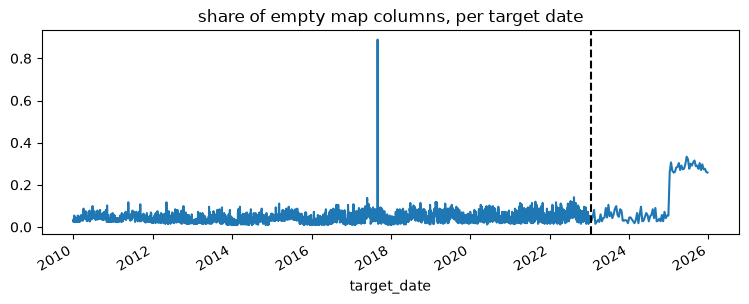

In [9]:
seen = test["station"].isin(train["station"].unique())
print(f"test rows whose station is in train.parquet: {seen.mean():.1%}")
st_new = stations[stations["station"].isin(test.loc[~seen, "station"])]
print(f"new stations: {len(st_new)}, departments {sorted(st_new['dep'].unique())}")

missing_by_date = maps.set_index("target_date")[map_cols].isna().mean(axis=1)
missing_by_date.plot(figsize=(9, 3), title="share of empty map columns, per target date")
plt.axvline(test["target_date"].min(), color="k", ls="--"); plt.show()

**Questions.** How does this starter predict a station it has never seen? What does the median imputation feed
the PCA when a quarter of the map is missing? How would you build a validation that tells you?

## 5. Submissions

We refit on all the training data (still subsampled) and predict the test set: the amount for track 1, the
probability of rain for track 2. On the new stations, is this probability still calibrated?

In [10]:
full = train if len(train) <= SAMPLE else train.sample(SAMPLE, random_state=1)
map_pca.fit(maps.loc[maps["target_date"].isin(train["target_date"]), map_cols])
Z = pd.DataFrame(map_pca.transform(maps[map_cols]), index=maps["target_date"]).add_prefix("pc")
X_full, y_full = design(full), full["rr"].to_numpy()
rain_full = y_full >= THRESHOLD
clf.fit(X_full, rain_full)
reg.fit(X_full[rain_full], np.log1p(y_full[rain_full]))
m0 = float(np.log1p(y_full[~rain_full]).mean())

X_te = design(test)
p_te = clf.predict_proba(X_te)[:, 1]
pred = np.expm1(p_te * np.clip(reg.predict(X_te), 0, None) + (1 - p_te) * m0)
OUT = Path(os.environ.get("PDD_OUT", "submission.csv"))
OUT_RAIN = Path(os.environ.get("PDD_OUT_RAIN", "submission_rain.csv"))
pd.DataFrame({"id": test["id"], "rr": pred}).to_csv(OUT, index=False)              # track 1: RMSLE
pd.DataFrame({"id": test["id"], "rain": p_te}).to_csv(OUT_RAIN, index=False)       # track 2: Brier score
print(OUT, "and", OUT_RAIN, "written", pred.shape)

c:\Users\gdest\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['n_07005' 'n_07558']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\gdest\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['n_07005' 'n_07558']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


submission.csv and submission_rain.csv written (149108,)
